In [1]:
import importlib, subprocess, sys

needed = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
          "scipy": "scipy", "uproot": "uproot", "awkward": "awkward",
          "fsspec_xrootd": "fsspec-xrootd"}
missing = []
for mod, pipname in needed.items():
    try:
        importlib.import_module(mod)
        print(f"OK       {mod}")
    except ImportError:
        print(f"MISSING  {mod}")
        missing.append(pipname)

if missing:
    print("\nInstalling:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + missing)
    print("Done. If imports fail in the next cell: Runtime -> Restart session, then rerun from Cell 2.")
else:
    print("\nNothing to install.")

OK       numpy
OK       pandas
OK       matplotlib
OK       scipy
MISSING  uproot
MISSING  awkward
MISSING  fsspec_xrootd

Installing: ['uproot', 'awkward', 'fsspec-xrootd']
Done. If imports fail in the next cell: Runtime -> Restart session, then rerun from Cell 2.


In [2]:
!pip install -q uproot awkward fsspec-xrootd

In [3]:
import uproot
import awkward as ak
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy

print("uproot", uproot.__version__, "| awkward", ak.__version__, "| numpy", np.__version__)

uproot 5.7.7 | awkward 2.14.0 | numpy 2.1.3


In [4]:
URL = "root://eospublic.cern.ch//eos/root-eos/cms_opendata_2012_nanoaod/Run2012B_DoubleMuParked.root"
tree = uproot.open(URL)["Events"]
print("Events:", f"{tree.num_entries:,}")

branches = ["nMuon", "Muon_pt", "Muon_eta", "Muon_phi", "Muon_mass", "Muon_charge"]
if "Muon_isGlobal" in tree.keys():
    branches.append("Muon_isGlobal")
print("Branches to read:", branches)

Events: 29,308,627
Branches to read: ['nMuon', 'Muon_pt', 'Muon_eta', 'Muon_phi', 'Muon_mass', 'Muon_charge']


In [5]:
def to_p4(pt, eta, phi, mass):
    px = pt * np.cos(phi)
    py = pt * np.sin(phi)
    pz = pt * np.sinh(eta)
    E  = np.sqrt(px**2 + py**2 + pz**2 + mass**2)
    return px, py, pz, E

def invariant_mass(mu1, mu2):
    p1 = to_p4(mu1.pt, mu1.eta, mu1.phi, mu1.mass)
    p2 = to_p4(mu2.pt, mu2.eta, mu2.phi, mu2.mass)
    E  = p1[3] + p2[3]
    px = p1[0] + p2[0]
    py = p1[1] + p2[1]
    pz = p1[2] + p2[2]
    m2 = E**2 - px**2 - py**2 - pz**2
    return np.sqrt(np.maximum(m2, 0))   # clip tiny negative rounding errors
print("functions defined")

functions defined


In [6]:
mu1 = ak.zip({"pt": ak.Array([45.59]), "eta": ak.Array([0.0]), "phi": ak.Array([0.0]),   "mass": ak.Array([0.10566])})
mu2 = ak.zip({"pt": ak.Array([45.59]), "eta": ak.Array([0.0]), "phi": ak.Array([np.pi]), "mass": ak.Array([0.10566])})
print(invariant_mass(mu1, mu2).tolist())

[91.18024487871483]


In [7]:
events = tree.arrays(branches, entry_stop=100_000)

muons = ak.zip({
    "pt":     events["Muon_pt"],
    "eta":    events["Muon_eta"],
    "phi":    events["Muon_phi"],
    "mass":   events["Muon_mass"],
    "charge": events["Muon_charge"],
})
print("events:", len(events))
print("muons per event, first 10:", ak.num(muons)[:10].tolist())
print("total muons:", int(ak.sum(ak.num(muons))))

events: 100000
muons per event, first 10: [2, 1, 2, 2, 2, 2, 2, 2, 2, 2]
total muons: 236475


In [8]:
pairs = ak.combinations(muons, 2, fields=["mu1", "mu2"])
os_mask = (pairs.mu1.charge * pairs.mu2.charge) < 0
os_pairs = pairs[os_mask]

n_os = ak.to_numpy(ak.num(os_pairs))
print("OS pairs per event -> number of events:")
for k, c in enumerate(np.bincount(n_os)[:6]):
    print(f"  {k} pairs: {c}")

mass = ak.to_numpy(ak.flatten(invariant_mass(os_pairs.mu1, os_pairs.mu2)))
print(f"\n{len(mass)} OS dimuon candidates | mass min {mass.min():.3f}, max {mass.max():.1f} GeV")

OS pairs per event -> number of events:
  0 pairs: 33366
  1 pairs: 36814
  2 pairs: 18162
  3 pairs: 4231
  4 pairs: 3947
  5 pairs: 214

131131 OS dimuon candidates | mass min 0.000, max 2357.7 GeV


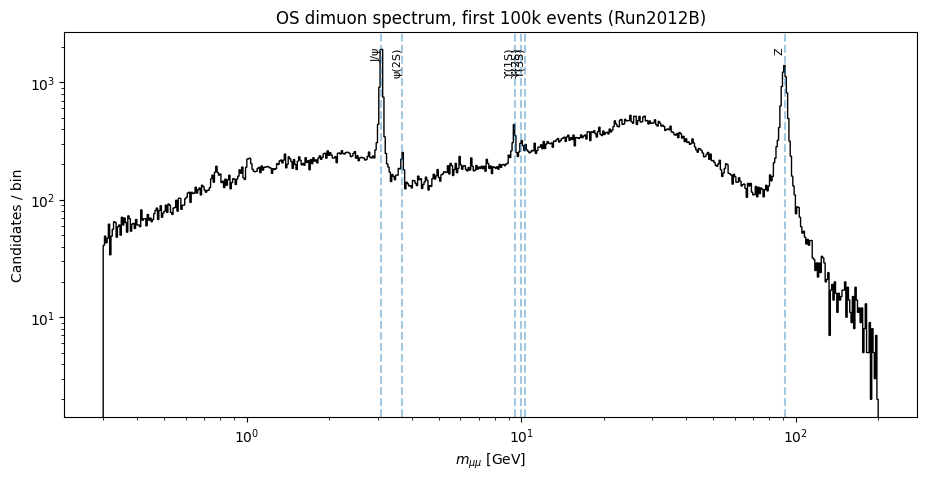

In [9]:
bins = np.logspace(np.log10(0.3), np.log10(200), 600)
refs = {"J/ψ": 3.097, "ψ(2S)": 3.686, "ϒ(1S)": 9.460, "ϒ(2S)": 10.023, "ϒ(3S)": 10.355, "Z": 91.19}

fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(mass, bins=bins, histtype="step", color="k")
for name, x in refs.items():
    ax.axvline(x, ls="--", alpha=0.4)
    ax.text(x, ax.get_ylim()[1], name, rotation=90, va="top", ha="right", fontsize=8)
ax.set(xscale="log", yscale="log", xlabel=r"$m_{\mu\mu}$ [GeV]", ylabel="Candidates / bin",
       title="OS dimuon spectrum, first 100k events (Run2012B)")
plt.savefig("day1_dimuon_spectrum_first_look.png", dpi=200)
plt.show()

In [11]:
def select_muons(ev):
    m = ak.zip({k: ev[f"Muon_{k}"] for k in ["pt", "eta", "phi", "mass", "charge"]})
    good = (m.pt > 3.0) & (np.abs(m.eta) < 2.4)
    if "Muon_isGlobal" in ev.fields:
        good = good & ev["Muon_isGlobal"]
    return m[good]

def dimuon_masses(ev):
    mu = select_muons(ev)
    pr = ak.combinations(mu, 2, fields=["mu1", "mu2"])
    pr = pr[(pr.mu1.charge * pr.mu2.charge) < 0]
    return ak.to_numpy(ak.flatten(invariant_mass(pr.mu1, pr.mu2)))

mass_sel = dimuon_masses(events)
print(f"before cuts: {len(mass)} candidates | after cuts: {len(mass_sel)}")

before cuts: 131131 candidates | after cuts: 128562


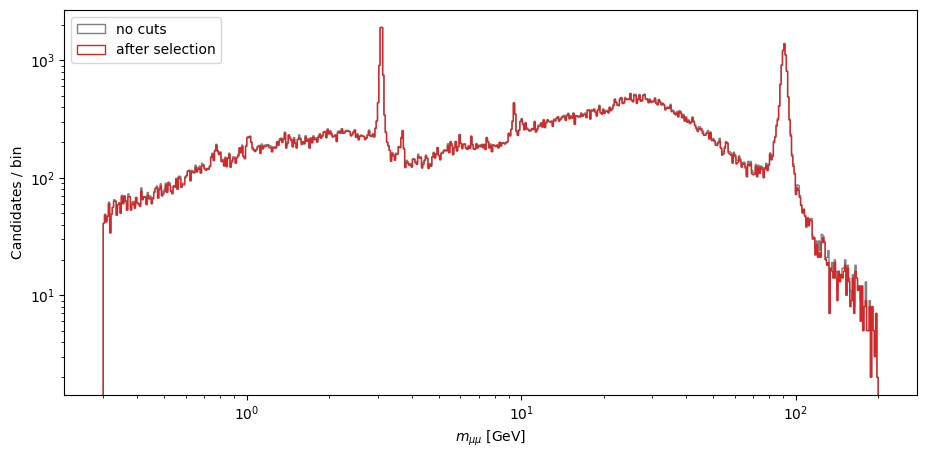

In [12]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(mass,     bins=bins, histtype="step", color="gray", label="no cuts")
ax.hist(mass_sel, bins=bins, histtype="step", color="C3",   label="after selection")
ax.set(xscale="log", yscale="log", xlabel=r"$m_{\mu\mu}$ [GeV]", ylabel="Candidates / bin")
ax.legend()
plt.show()

In [13]:
import time
N_TOTAL = 1_000_000
counts = np.zeros(len(bins) - 1)
n_events = 0
t0 = time.time()

for chunk in tree.iterate(branches, step_size=100_000, entry_stop=N_TOTAL):
    m = dimuon_masses(chunk)
    counts += np.histogram(m, bins=bins)[0]
    n_events += len(chunk)
    print(f"processed {n_events:,} events  ({time.time()-t0:.0f}s)")

processed 100,000 events  (3s)
processed 200,000 events  (3s)
processed 300,000 events  (4s)
processed 400,000 events  (4s)
processed 500,000 events  (5s)
processed 600,000 events  (5s)
processed 700,000 events  (5s)
processed 800,000 events  (6s)
processed 900,000 events  (6s)
processed 1,000,000 events  (7s)


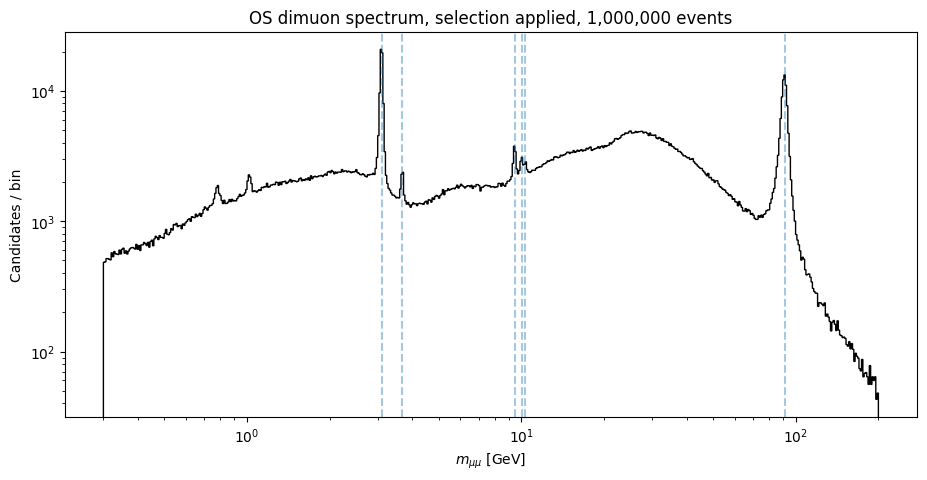

In [14]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.stairs(counts, bins, color="k")
for name, x in refs.items():
    ax.axvline(x, ls="--", alpha=0.4)
ax.set(xscale="log", yscale="log", xlabel=r"$m_{\mu\mu}$ [GeV]", ylabel="Candidates / bin",
       title=f"OS dimuon spectrum, selection applied, {n_events:,} events")
plt.savefig("day1_dimuon_spectrum.png", dpi=200)
plt.show()

In [15]:
np.savez("day1_dimuon_hist_1M.npz", counts=counts, bins=bins, n_events=n_events)
print("saved; total entries in histogram:", int(counts.sum()))

saved; total entries in histogram: 1271703


In [17]:
from google.colab import drive
import os, shutil

drive.mount("/content/drive")
OUT = "/content/drive/MyDrive/cms-dimuon-resonances/results"
os.makedirs(OUT + "/figures", exist_ok=True)
shutil.copy("day1_dimuon_hist_1M.npz", OUT)
for f in ["day1_dimuon_spectrum_first_look.png", "day1_dimuon_spectrum.png"]:
    shutil.copy(f, OUT + "/figures")
print(os.listdir(OUT), os.listdir(OUT + "/figures"))

Mounted at /content/drive
['figures', 'day1_dimuon_hist_1M.npz'] ['day1_dimuon_spectrum_first_look.png', 'day1_dimuon_spectrum.png']


In [18]:
import time

N_TOTAL = tree.num_entries
regions = {                   # fine linear bins for Day 2 fits
    "jpsi_psi2s": np.arange(2.6, 4.0 + 1e-9, 0.01),    # 10 MeV bins
    "upsilon":    np.arange(8.5, 11.5 + 1e-9, 0.02),   # 20 MeV bins
    "z":          np.arange(60.0, 120.0 + 1e-9, 0.5),  # 0.5 GeV bins
}

counts_big = np.zeros(len(bins) - 1)
reg_counts = {k: np.zeros(len(v) - 1) for k, v in regions.items()}
n_big = 0
t0 = time.time()

for chunk in tree.iterate(branches, step_size=200_000, entry_stop=N_TOTAL):
    m = dimuon_masses(chunk)
    counts_big += np.histogram(m, bins=bins)[0]
    for k, edges in regions.items():
        reg_counts[k] += np.histogram(m, bins=edges)[0]
    n_big += len(chunk)
    if (n_big // 200_000) % 5 == 0:
        print(f"processed {n_big:,} events  ({time.time()-t0:.0f}s)")

print(f"done: {n_big:,} events in {time.time()-t0:.0f}s")

processed 1,000,000 events  (12s)
processed 2,000,000 events  (17s)
processed 3,000,000 events  (22s)
processed 4,000,000 events  (27s)
processed 5,000,000 events  (32s)
processed 6,000,000 events  (38s)
processed 7,000,000 events  (43s)
processed 8,000,000 events  (49s)
processed 9,000,000 events  (56s)
processed 10,000,000 events  (62s)
processed 11,000,000 events  (68s)
processed 12,000,000 events  (74s)
processed 13,000,000 events  (79s)
processed 14,000,000 events  (84s)
processed 15,000,000 events  (90s)
processed 16,000,000 events  (95s)
processed 17,000,000 events  (100s)
processed 18,000,000 events  (105s)
processed 19,000,000 events  (110s)
processed 20,000,000 events  (116s)
processed 21,000,000 events  (122s)
processed 22,000,000 events  (128s)
processed 23,000,000 events  (133s)
processed 24,000,000 events  (139s)
processed 25,000,000 events  (145s)
processed 26,000,000 events  (151s)
processed 27,000,000 events  (157s)
processed 28,000,000 events  (163s)
processed 29,000,

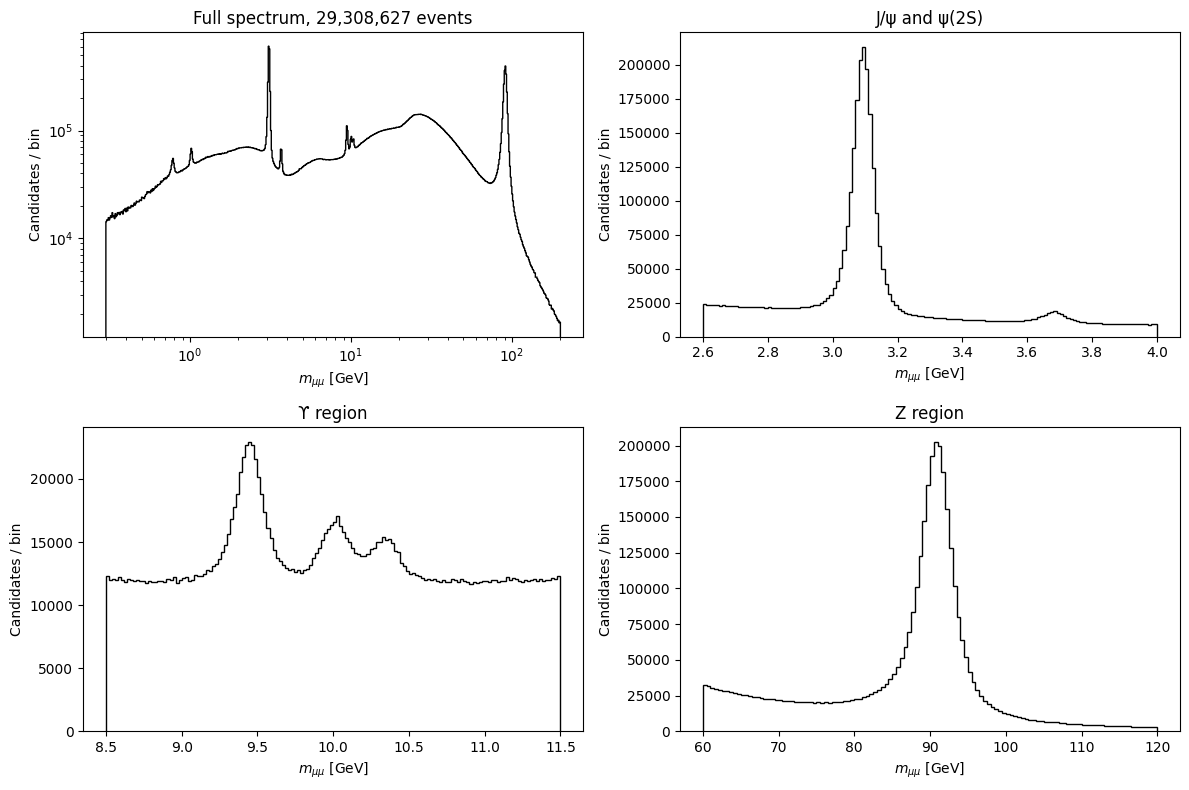

In [19]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

ax[0,0].stairs(counts_big, bins, color="k")
ax[0,0].set(xscale="log", yscale="log", xlabel=r"$m_{\mu\mu}$ [GeV]", ylabel="Candidates / bin",
            title=f"Full spectrum, {n_big:,} events")

for a, (k, edges), title in zip([ax[0,1], ax[1,0], ax[1,1]], regions.items(),
                                ["J/ψ and ψ(2S)", "ϒ region", "Z region"]):
    a.stairs(reg_counts[k], edges, color="k")
    a.set(xlabel=r"$m_{\mu\mu}$ [GeV]", ylabel="Candidates / bin", title=title)

plt.tight_layout()
plt.savefig("day1_dimuon_spectrum_full.png", dpi=200)
plt.show()

In [20]:
np.savez("day1_dimuon_hist_full.npz", counts=counts_big, bins=bins, n_events=n_big,
         **{f"reg_{k}": v for k, v in reg_counts.items()},
         **{f"edges_{k}": v for k, v in regions.items()})
shutil.copy("day1_dimuon_hist_full.npz", OUT)
shutil.copy("day1_dimuon_spectrum_full.png", OUT + "/figures")
print(os.listdir(OUT), os.listdir(OUT + "/figures"))

['figures', 'day1_dimuon_hist_1M.npz', 'day1_dimuon_hist_full.npz'] ['day1_dimuon_spectrum_first_look.png', 'day1_dimuon_spectrum.png', 'day1_dimuon_spectrum_full.png']


In [21]:
print("events processed:", f"{n_big:,}", "| file has:", f"{tree.num_entries:,}")
print("total entries, log histogram:", int(counts_big.sum()))
for k, v in reg_counts.items():
    print(f"{k:12s} entries in fit window: {int(v.sum()):,}")

import os
print("\nDrive results:", os.listdir(OUT) if "OUT" in globals() else "Drive not mounted")
print("Drive figures:", os.listdir(OUT + "/figures") if "OUT" in globals() else "-")

events processed: 29,308,627 | file has: 29,308,627
total entries, log histogram: 37215744
jpsi_psi2s   entries in fit window: 3,816,903
upsilon      entries in fit window: 2,024,739
z            entries in fit window: 3,928,874

Drive results: ['figures', 'day1_dimuon_hist_1M.npz', 'day1_dimuon_hist_full.npz']
Drive figures: ['day1_dimuon_spectrum_first_look.png', 'day1_dimuon_spectrum.png', 'day1_dimuon_spectrum_full.png']


In [22]:
d = np.load(OUT + "/day1_dimuon_hist_full.npz")
print(d.files)
print("n_events:", int(d["n_events"]), "| entries match:", int(d["counts"].sum()) == int(counts_big.sum()))

['counts', 'bins', 'n_events', 'reg_jpsi_psi2s', 'reg_upsilon', 'reg_z', 'edges_jpsi_psi2s', 'edges_upsilon', 'edges_z']
n_events: 29308627 | entries match: True


## Day 1 summary: dimuon invariant-mass spectrum (Run2012B, full file)

**Data and selection.** I processed all 29,308,627 events of the CMS 2012 Run2012B
DoubleMuParked open-data file by streaming it with uproot in chunks of 200,000 events.
Muons were required to have pT > 3 GeV and |η| < 2.4 (plus the global-muon flag, if
present in the file). Muon pairs were formed with opposite charge, and the invariant
mass was computed from the four-vectors built from pT, η, φ and mass. The mass function
was checked with a two-muon test case that gave about 91.18 GeV.

**What the spectrum shows.**
- **J/ψ and ψ(2S):** a strong J/ψ peak near 3.1 GeV and a separate, much smaller ψ(2S)
  peak near 3.7 GeV, both sitting on a smooth continuum.
- **ϒ family:** three resolved peaks at roughly 9.45, 10.0 and 10.35 GeV, which I
  attribute to ϒ(1S), ϒ(2S) and ϒ(3S). Day 2 fits will give the actual masses.
- **Z boson:** a single peak near 91 GeV with a tail towards lower mass.
- **Extra low-mass structures:** two small peaks near 0.8 and 1.0 GeV in the full
  spectrum. I have not identified them yet.
- **Broad hump at ~20–40 GeV:** this is not a resonance. It is a wide, smooth shape in
  the background, shaped by detector acceptance, trigger thresholds and the falling
  production rate, so it will be handled in the background model.

**Numbers from this run.** The log-binned histogram has 37,215,744 opposite-sign pair
candidates from 29,308,627 events (about 1.27 candidates per event). The fit windows
contain 3,816,903 (J/ψ + ψ(2S)), 2,024,739 (ϒ) and 3,928,874 (Z) candidates.
The basic selection removed about 2% of candidates in a 100,000-event test
(131,131 → 128,562). This is not a measured efficiency or purity.

**Limitations to carry forward.**
- Events with more than two muons contribute more than one pair, so the histogram counts
  candidate pairs, not events. A rule for choosing one pair per event is needed.
- Peak positions above are read from the plots, not measured.
- No trigger or efficiency corrections have been applied, so yields are not cross sections.
- Only Run2012B is used so far; Run2012C could add statistics.

**Saved outputs.** `day1_dimuon_hist_full.npz` (histograms and fit-window histograms)
and the figures in `results/figures/`.